# ISE 521 · Konu 17 · Self-Attention ve Transformer

Self-Attention mekanizması yalnızca **NumPy** ile sıfırdan uygulanır: Q/K/V, skorlar, `√d_k` ölçeklemesi, softmax, çıktı, gradyan doygunluğu, çok başlı dikkat ve `O(T²)` karmaşıklığı.

**Sınır:** Girdiler ve ağırlıklar rastgeledir, eğitim yoktur. Isı haritaları dilsel anlam göstermez; yalnızca mekanizmayı gösterir.

**Çalıştırma:** *Run All*. Harici veri veya kütüphane gerekmez; tohumlar sabittir.

## 01 · Neden self-attention?

- **RNN/LSTM** diziyi sırayla işler; uzak bağlar ve paralel hesap zordur.
- **Self-attention**'da her token'ın Query'si tüm Key'lerle karşılaştırılır; Value'lar bu ağırlıklarla birleştirilir.
- Self-attention, Transformer'ın bir parçasıdır; tamamı değildir.

Akış: `X → Q, K, V → QKᵀ → /√d_k → softmax → A·V → çok başlı dikkat → karmaşıklık`

## 02 · Boyutlar

| Sembol | Anlamı | Değer |
|---|---|---:|
| `T` | token sayısı | 6 |
| `d_model` | token vektörünün uzunluğu | 8 |
| `d_k` | Query/Key vektörünün uzunluğu | 4 |
| `d_v` | Value vektörünün uzunluğu | 4 |

`d_k = 4` bizim seçtiğimiz bir parametredir; `√d_k = 2` ondan hesaplanır.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

T, D_MODEL, D_K, D_V = 6, 8, 4, 4
tokens = ["Bu", "bir", "dikkat", "mekanizması", "örneği", "dir"]
X = rng.normal(size=(T, D_MODEL))

np.set_printoptions(precision=3, suppress=True)
print("Tokens:", tokens)
print("X shape:", X.shape, "\nFirst token embedding:", X[0])

Tokens: ['Bu', 'bir', 'dikkat', 'mekanizması', 'örneği', 'dir']
X shape: (6, 8) 
First token embedding: [ 0.305 -1.04   0.75   0.941 -1.951 -1.302  0.128 -0.316]


## 03 · Q, K, V izdüşümleri

`Q = X·W_Q`, `K = X·W_K`, `V = X·W_V`: üç ayrı ağırlık matrisi. Burada rastgele; gerçek modellerde eğitimle öğrenilir.

\[
(6\times8)(8\times4)=(6\times4)
\]

In [2]:
Wq = rng.normal(size=(D_MODEL, D_K)) / np.sqrt(D_MODEL)
Wk = rng.normal(size=(D_MODEL, D_K)) / np.sqrt(D_MODEL)
Wv = rng.normal(size=(D_MODEL, D_V)) / np.sqrt(D_MODEL)

Q, K, V = X @ Wq, X @ Wk, X @ Wv
print("Wq:", Wq.shape, "| Q:", Q.shape)
print("Wk:", Wk.shape, "| K:", K.shape)
print("Wv:", Wv.shape, "| V:", V.shape)

# İlk elemanı elle doğrula
q00_manual = sum(X[0, r] * Wq[r, 0] for r in range(D_MODEL))
print("Q[0,0] manually:", round(q00_manual, 6))
print("Q[0,0] by matrix:", round(float(Q[0, 0]), 6))
assert np.isclose(q00_manual, Q[0, 0])

Wq: (8, 4) | Q: (6, 4)
Wk: (8, 4) | K: (6, 4)
Wv: (8, 4) | V: (6, 4)
Q[0,0] manually: -0.903091
Q[0,0] by matrix: -0.903091


## 04 · Skorlar: `Q·Kᵀ`

\[
S_{raw}=QK^T,\quad (6\times4)(4\times6)=(6\times6)
\]

`S_raw[i, j] = Q[i] · K[j]`: i. token'ın Query'si ile j. token'ın Key'inin ham skoru. `K.T` devriktir (transpose).

In [3]:
S_raw = Q @ K.T
print("Q:", Q.shape, "K.T:", K.T.shape, "Scores:", S_raw.shape)
print("S_raw[2,4]:", round(float(S_raw[2,4]), 6))
print("Q[2] dot K[4]:", round(float(np.dot(Q[2], K[4])), 6))
assert np.isclose(S_raw[2,4], np.dot(Q[2], K[4]))
print("Raw Scores (6×6):\n", S_raw)

Q: (6, 4) K.T: (4, 6) Scores: (6, 6)
S_raw[2,4]: -1.22594
Q[2] dot K[4]: -1.22594
Raw Scores (6×6):
 [[-2.168 -0.76  -0.881 -0.506 -1.544 -0.503]
 [ 0.596  0.679 -0.192  0.298 -0.429  0.199]
 [-0.555  0.28  -0.728 -0.469 -1.226 -0.731]
 [-0.777  0.825 -0.639  0.758 -1.31   0.215]
 [-1.153 -0.124 -0.472 -0.042 -0.848 -0.25 ]
 [-0.659 -0.232 -0.04   0.206 -0.119  0.179]]


## 05 · Ölçekleme: neden `√d_k`?

\[
Z=\frac{QK^T}{\sqrt{d_k}},\qquad d_k=4 \Rightarrow \sqrt{4}=2
\]

Q ve K bileşenleri bağımsız, ortalaması 0 ve varyansı 1 ise `Var(q·k) = d_k` olur. `√d_k` ile bölmek varyansı 1'e indirir.

In [4]:
Z = S_raw / np.sqrt(D_K)
print("d_k =", D_K, "| divisor =", np.sqrt(D_K))
print("Scores before scaling, first row:", S_raw[0])
print("Scores after scaling, first row: ", Z[0])
print("Attention score matrix remains:", Z.shape)

d_k = 4 | divisor = 2.0
Scores before scaling, first row: [-2.168 -0.76  -0.881 -0.506 -1.544 -0.503]
Scores after scaling, first row:  [-1.084 -0.38  -0.44  -0.253 -0.772 -0.252]
Attention score matrix remains: (6, 6)


## 06 · Softmax (satır satır)

\[
A_{ij}=\frac{e^{Z_{ij}}}{\sum_{m=1}^{T} e^{Z_{im}}}
\]

Her Query satırı ayrı normalize edilir; satır toplamı 1'dir. Taşmayı önlemek için önce satırın en büyük değeri çıkarılır; sonuç değişmez.

In [5]:
def softmax_rows(z):
    """Stable row-wise Softmax implemented with NumPy only."""
    z = np.asarray(z, dtype=np.float64)
    shifted = z - np.max(z, axis=-1, keepdims=True)
    exps = np.exp(shifted)
    return exps / np.sum(exps, axis=-1, keepdims=True)

# Tek satırı ara adımlarıyla hesapla
row = Z[0]
shifted = row - np.max(row)
exps = np.exp(shifted)
manual_weights = exps / np.sum(exps)

print("1. Scores:       ", row)
print("2. Shifted:      ", shifted)
print("3. Exponentials: ", exps)
print("4. Row weights:  ", manual_weights)
print("5. Sum:          ", manual_weights.sum())

A = softmax_rows(Z)
print("Attention A shape:", A.shape)
print("Sum of every row:", A.sum(axis=1))
assert np.allclose(A[0], manual_weights)
assert np.allclose(A.sum(axis=1), np.ones(T))

1. Scores:        [-1.084 -0.38  -0.44  -0.253 -0.772 -0.252]
2. Shifted:       [-0.832 -0.129 -0.189 -0.002 -0.521  0.   ]
3. Exponentials:  [0.435 0.879 0.828 0.998 0.594 1.   ]
4. Row weights:   [0.092 0.186 0.175 0.211 0.125 0.211]
5. Sum:           1.0
Attention A shape: (6, 6)
Sum of every row: [1. 1. 1. 1. 1. 1.]


## 07 · Dikkat çıktısı: `O = A·V`

\[
O=AV,\qquad (6\times6)(6\times4)=(6\times4)
\]

Her çıktı satırı, Value satırlarının ağırlıklı toplamıdır.

In [6]:
O = A @ V
manual_third = sum(A[2, j] * V[j] for j in range(T))
print("O shape:", O.shape)
print("Third output:", O[2])
print("Manually combined:", manual_third)
assert O.shape == (T, D_V)
assert np.allclose(O[2], manual_third)

O shape: (6, 4)
Third output: [0.003 0.447 0.744 0.908]
Manually combined: [0.003 0.447 0.744 0.908]


## 08 · Isı haritası

Satır = Query token'ı, sütun = Key token'ı, renk = dikkat ağırlığı. Sentetik bir deneydir; renkler dilsel anlam taşımaz.

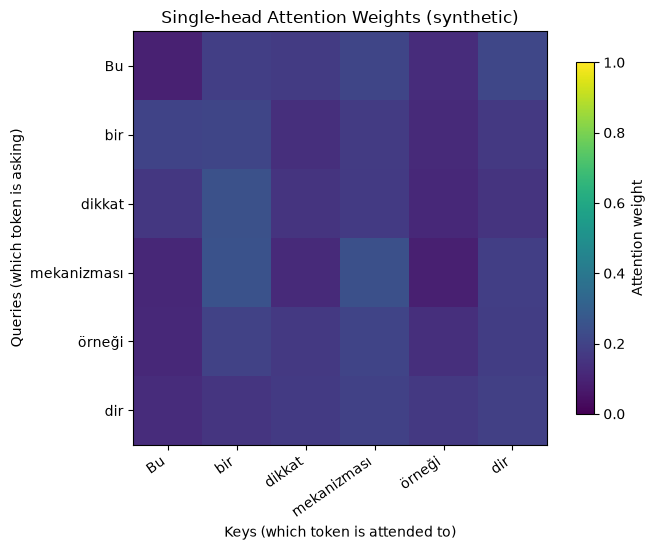

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 5.6))
im = ax.imshow(A, cmap="viridis", vmin=0, vmax=1, aspect="equal")
ax.set_xticks(range(T), tokens, rotation=35, ha="right")
ax.set_yticks(range(T), tokens)
ax.set_xlabel("Keys (which token is attended to)")
ax.set_ylabel("Queries (which token is asking)")
ax.set_title("Single-head Attention Weights (synthetic)")
fig.colorbar(im, ax=ax, label="Attention weight", shrink=0.85)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_attention_heatmap.png", dpi=300)
plt.show()

## 09 · `√d_k` gerekçesinin sayısal testi

Rastgele q, k çiftleriyle: ölçekleme yokken standart sapma `√d_k` ile büyür, ölçekleme varken ≈ 1 kalır.

d_k=  4 | raw std= 1.966 | scaled std= 0.983 | theoretical raw std= 2.00
d_k= 16 | raw std= 4.072 | scaled std= 1.018 | theoretical raw std= 4.00
d_k= 64 | raw std= 8.032 | scaled std= 1.004 | theoretical raw std= 8.00
d_k=256 | raw std=16.257 | scaled std= 1.016 | theoretical raw std=16.00


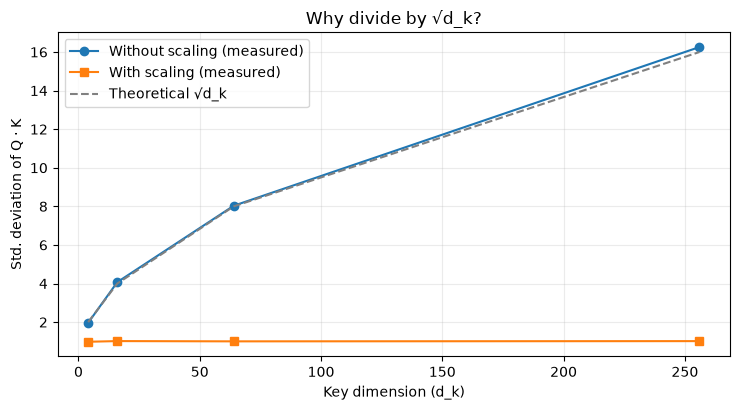

In [8]:
dims = [4, 16, 64, 256]
raw_stds, scaled_stds = [], []
rng_stats = np.random.default_rng(123)

for dk in dims:
    q = rng_stats.normal(size=(3000, dk))
    k = rng_stats.normal(size=(3000, dk))
    scores = (q * k).sum(axis=1)
    raw_stds.append(scores.std())
    scaled_stds.append((scores / np.sqrt(dk)).std())
    print(f"d_k={dk:3d} | raw std={raw_stds[-1]:6.3f} "
          f"| scaled std={scaled_stds[-1]:6.3f} "
          f"| theoretical raw std={np.sqrt(dk):5.2f}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(dims, raw_stds, "o-", label="Without scaling (measured)")
ax.plot(dims, scaled_stds, "s-", label="With scaling (measured)")
ax.plot(dims, np.sqrt(dims), "--", color="gray", label="Theoretical √d_k")
ax.set_xlabel("Key dimension (d_k)")
ax.set_ylabel("Std. deviation of Q · K")
ax.set_title("Why divide by √d_k?")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_scaling_std.png", dpi=300)
plt.show()

## 10 · Softmax doygunluğu ve Jacobian

\[
J=\operatorname{diag}(p)-pp^T,\qquad J_{ii}=p_i(1-p_i)
\]

Jacobian ayrı bir dikkat adımı değildir; softmax'ın türevlerini gösterir ve geri yayılımda kullanılır. Skorlar çok ayrışınca `p ≈ [1, 0, 0]` olur ve türevler sıfıra yaklaşır: **gradyan doygunluğu**. Bu, tüm ağın öğrenmesinin durduğu anlamına gelmez.


 Without scaling scores: [20. 10.  0.]
Softmax: ['0.9999546', '4.53978686e-05', '2.06106005e-09']
Jacobian diagonal: ['4.53978685e-05', '4.53958076e-05', '2.06106004e-09']
Jacobian trace: 9.079573721786321e-05

 With scaling scores: [2. 1. 0.]
Softmax: ['0.665240956', '0.244728471', '0.0900305732']
Jacobian diagonal: ['0.222695427', '0.184836447', '0.0819250691']
Jacobian trace: 0.48945694210959534


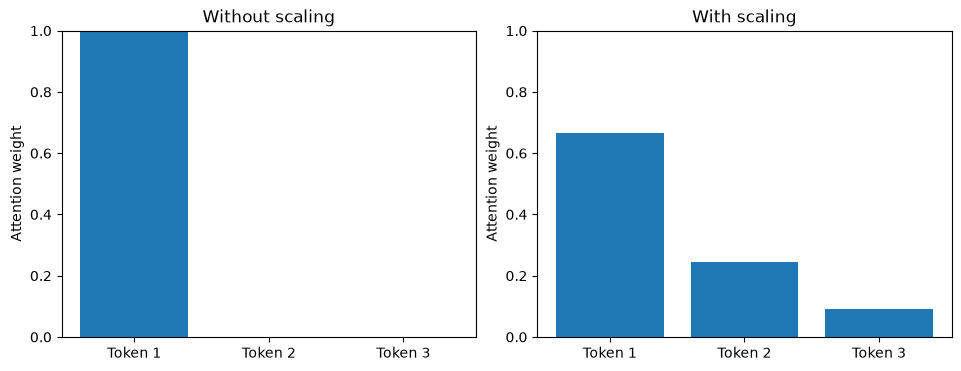

In [9]:
def softmax_jacobian(p):
    """Jacobian of a softmax probability vector."""
    return np.diag(p) - np.outer(p, p)

example_raw = np.array([20., 10., 0.])
example_scaled = example_raw / np.sqrt(100)  # divide by 10

for label, z in [("Without scaling", example_raw),
                 ("With scaling", example_scaled)]:
    p = softmax_rows(z)
    J = softmax_jacobian(p)
    print("\n", label, "scores:", z)
    print("Softmax:", [f"{v:.9g}" for v in p])
    print("Jacobian diagonal:", [f"{v:.9g}" for v in np.diag(J)])
    print("Jacobian trace:", np.trace(J))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), layout="constrained")
for ax, z, title in zip(axes, [example_raw, example_scaled],
                       ["Without scaling", "With scaling"]):
    ax.bar(["Token 1", "Token 2", "Token 3"], softmax_rows(z))
    ax.set_ylim(0, 1)
    ax.set_ylabel("Attention weight")
    ax.set_title(title)
fig.savefig(FIG_DIR / "03_softmax_saturation_example.png", dpi=300)
plt.show()

### Jacobian doğrulaması (sonlu farklar)

\[
\frac{\partial p_i}{\partial z_j}\approx\frac{p_i(z+\varepsilon e_j)-p_i(z-\varepsilon e_j)}{2\varepsilon},\qquad \varepsilon=10^{-6}
\]

Analitik formül sayısal türevle karşılaştırılır; fark ≈ 0 olmalıdır.

In [10]:
z_check = np.random.default_rng(7).normal(size=5)
J_analytic = softmax_jacobian(softmax_rows(z_check))
eps = 1e-6
J_numeric = np.zeros((5, 5))
for j in range(5):
    e_j = np.zeros(5)
    e_j[j] = eps
    J_numeric[:, j] = (softmax_rows(z_check + e_j) - softmax_rows(z_check - e_j)) / (2 * eps)

jacobian_fd_error = np.max(np.abs(J_analytic - J_numeric))
print("Max |analytic - numeric|:", jacobian_fd_error)
print("Row sums of J (should be 0):", J_analytic.sum(axis=1).round(12))
assert jacobian_fd_error < 1e-8

Max |analytic - numeric|: 4.148058285746714e-11
Row sums of J (should be 0): [ 0. -0. -0.  0.  0.]


## 11 · Deney: ölçekleme ile ve ölçeklemesiz

Aynı rastgele Q ve K ile iki koşul karşılaştırılır: `raw` ve `raw/√d_k`. Ölçü: Jacobian izi `1 − Σ p²`. Küçük iz, softmax'ın duyarlılığının zayıfladığını gösterir. Deney yalnızca softmax'ın türev davranışını ölçer.

d_k=  4 | Mean Jacobian trace: NO scaling=0.5476 | WITH scaling=0.7223
d_k= 16 | Mean Jacobian trace: NO scaling=0.3101 | WITH scaling=0.7201
d_k= 64 | Mean Jacobian trace: NO scaling=0.1594 | WITH scaling=0.7084
d_k=256 | Mean Jacobian trace: NO scaling=0.0916 | WITH scaling=0.7143


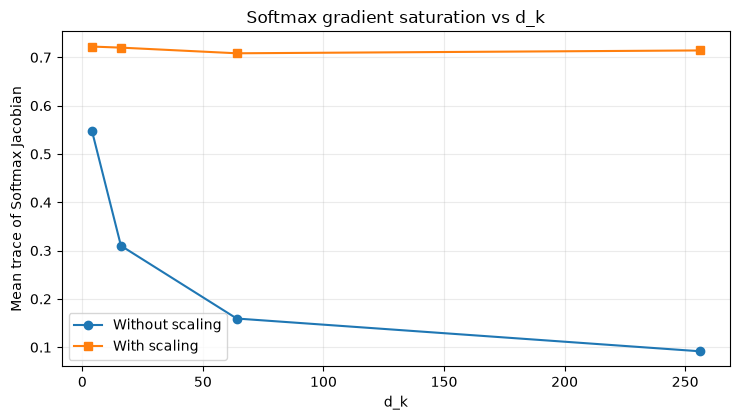

In [11]:
rng_sat = np.random.default_rng(321)
n_trials = 400
trace_no, trace_yes = [], []

for dk in dims:
    q = rng_sat.normal(size=(n_trials, 1, dk))
    k = rng_sat.normal(size=(n_trials, T, dk))
    scores = np.sum(q * k, axis=-1)  # (n_trials, T)

    no_scale = softmax_rows(scores)
    with_scale = softmax_rows(scores / np.sqrt(dk))

    # Trace(J) = 1 - sum(p_i^2) for each Softmax row
    mean_no = np.mean(1.0 - np.sum(no_scale**2, axis=1))
    mean_yes = np.mean(1.0 - np.sum(with_scale**2, axis=1))
    trace_no.append(mean_no)
    trace_yes.append(mean_yes)
    print(f"d_k={dk:3d} | Mean Jacobian trace: "
          f"NO scaling={mean_no:.4f} | WITH scaling={mean_yes:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(dims, trace_no, "o-", label="Without scaling")
ax.plot(dims, trace_yes, "s-", label="With scaling")
ax.set_xlabel("d_k")
ax.set_ylabel("Mean trace of Softmax Jacobian")
ax.set_title("Softmax gradient saturation vs d_k")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_gradient_saturation.png", dpi=300)
plt.show()

### Aynı skorlar, iki ısı haritası

Büyük `d_k` (256) için aynı Q ve K kullanılır; tek fark ölçeklemedir. Ölçeksiz harita daha keskindir.

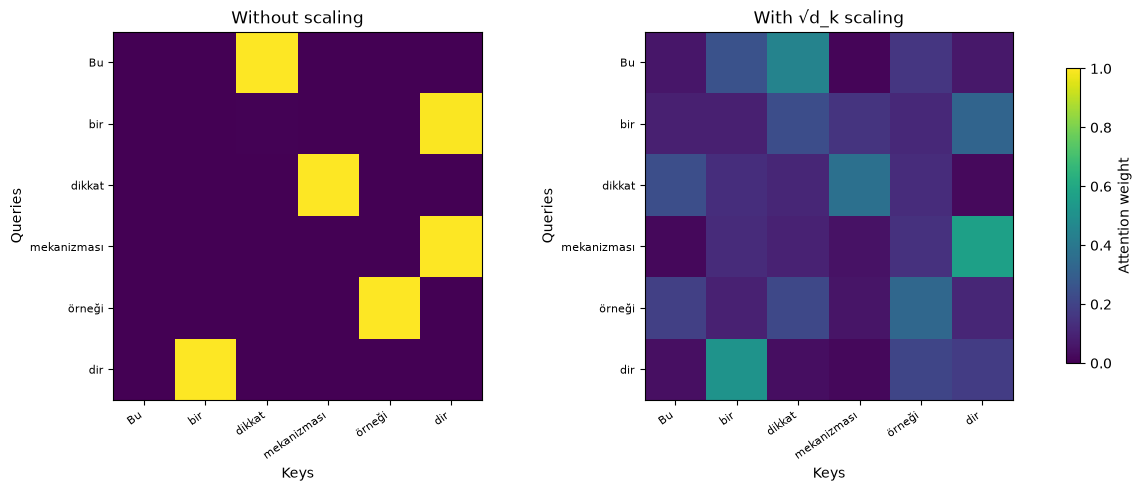

In [12]:
rng_heat = np.random.default_rng(55)
dk_heat = 256
Q_heat = rng_heat.normal(size=(T, dk_heat))
K_heat = rng_heat.normal(size=(T, dk_heat))
raw_heat = Q_heat @ K_heat.T
A_heat_no = softmax_rows(raw_heat)
A_heat_yes = softmax_rows(raw_heat / np.sqrt(dk_heat))

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.8), layout="constrained")
for ax, mat, title in zip(
    axes,
    [A_heat_no, A_heat_yes],
    ["Without scaling", "With √d_k scaling"]
):
    im = ax.imshow(mat, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(T), tokens, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(T), tokens, fontsize=8)
    ax.set_xlabel("Keys")
    ax.set_ylabel("Queries")
fig.colorbar(im, ax=axes, label="Attention weight", shrink=0.8)
fig.savefig(FIG_DIR / "05_scaling_heatmaps.png", dpi=300)
plt.show()

## 12 · Çok başlı dikkat (iki head)

Her head aynı X'i alır ama kendi `W_Q`, `W_K`, `W_V`'sini kullanır; her biri `6×6` bir dikkat matrisi ve `6×4` bir çıktı üretir.

\[
\operatorname{Concat}(O_1,O_2)=(6\times8),\qquad \operatorname{Concat}(O_1,O_2)\,W_O=(6\times8)(8\times8)=(6\times8)
\]

In [13]:
rng_heads = np.random.default_rng(777)
NUM_HEADS, HEAD_DIM = 2, 4
head_outputs, head_attentions = [], []
head_queries, head_keys = [], []

for head_idx in range(NUM_HEADS):
    # Each head gets its own independent projection weights
    wq = rng_heads.normal(size=(D_MODEL, HEAD_DIM)) / np.sqrt(D_MODEL)
    wk = rng_heads.normal(size=(D_MODEL, HEAD_DIM)) / np.sqrt(D_MODEL)
    wv = rng_heads.normal(size=(D_MODEL, HEAD_DIM)) / np.sqrt(D_MODEL)

    q, k, v = X @ wq, X @ wk, X @ wv
    a = softmax_rows((q @ k.T) / np.sqrt(HEAD_DIM))
    o = a @ v
    head_attentions.append(a)
    head_queries.append(q)
    head_keys.append(k)
    head_outputs.append(o)
    print(f"Head {head_idx + 1}: A={a.shape}, O={o.shape}")

concat = np.concatenate(head_outputs, axis=1)
Wo = rng_heads.normal(size=(NUM_HEADS * HEAD_DIM, D_MODEL)) / np.sqrt(NUM_HEADS * HEAD_DIM)
final_output = concat @ Wo

print("Concat shape:", concat.shape)
print("W_O shape:", Wo.shape)
print("Final MHA output shape:", final_output.shape)
print("Heads identical?", np.allclose(head_attentions[0], head_attentions[1]))

Head 1: A=(6, 6), O=(6, 4)
Head 2: A=(6, 6), O=(6, 4)
Concat shape: (6, 8)
W_O shape: (8, 8)
Final MHA output shape: (6, 8)
Heads identical? False


### İki head'in ısı haritaları

Ağırlıklar rastgele olduğu için fark, öğrenilmiş bir uzmanlaşma değildir.

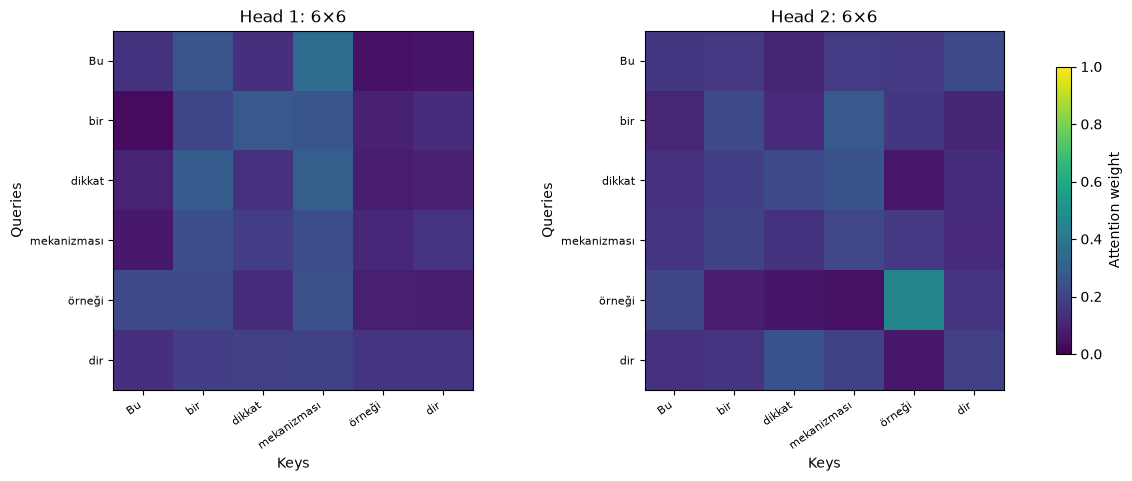

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.7), layout="constrained")
for idx, ax in enumerate(axes):
    im = ax.imshow(head_attentions[idx], cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"Head {idx + 1}: 6×6")
    ax.set_xticks(range(T), tokens, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(T), tokens, fontsize=8)
    ax.set_xlabel("Keys")
    ax.set_ylabel("Queries")
fig.colorbar(im, ax=axes, label="Attention weight", shrink=0.8)
fig.savefig(FIG_DIR / "06_multi_head_heatmaps.png", dpi=300)
plt.show()

### İki head neden tek geniş head ile aynı değil?

\[
Q_{wide}K_{wide}^T = Q_1K_1^T + Q_2K_2^T
\]

Tek geniş head bu toplamı tek bir softmax'tan geçirir. Çok başlı dikkat her alt uzaya ayrı softmax uygular; softmax doğrusal olmadığı için sonuç farklıdır.

In [15]:
Q_wide = np.concatenate(head_queries, axis=1)   # (6, 8)
K_wide = np.concatenate(head_keys, axis=1)      # (6, 8)
sum_of_head_scores = sum(q_h @ k_h.T for q_h, k_h in zip(head_queries, head_keys))
print("Q_wide K_wide^T == Q1 K1^T + Q2 K2^T ?", np.allclose(Q_wide @ K_wide.T, sum_of_head_scores))

A_one_wide = softmax_rows((Q_wide @ K_wide.T) / np.sqrt(NUM_HEADS * HEAD_DIM))
A_mean_heads = np.mean(head_attentions, axis=0)
print("Mean |one wide head - average of two heads|:", round(float(np.mean(np.abs(A_one_wide - A_mean_heads))), 4))
assert np.allclose(Q_wide @ K_wide.T, sum_of_head_scores)
assert not np.allclose(A_one_wide, A_mean_heads)

Q_wide K_wide^T == Q1 K1^T + Q2 K2^T ? True
Mean |one wide head - average of two heads|: 0.0223


## 13 · Karmaşıklık: `O(T²)`

`T` Query × `T` Key = `T²` skor. Zaman `O(T²·d_k)`, `T×T` matris için bellek `O(T²)`. Token sayısı iki katına çıkınca skor sayısı dört katına çıkar: `T = 6 → 36`, `T = 12 → 144`.

T=  6  ->  scores=    36
T= 12  ->  scores=   144
T= 24  ->  scores=   576
T= 48  ->  scores=  2304
T= 96  ->  scores=  9216
T=192  ->  scores= 36864
T=1024: one float32 attention matrix ≈ 4.0 MiB
T=2048: one float32 attention matrix ≈ 16.0 MiB


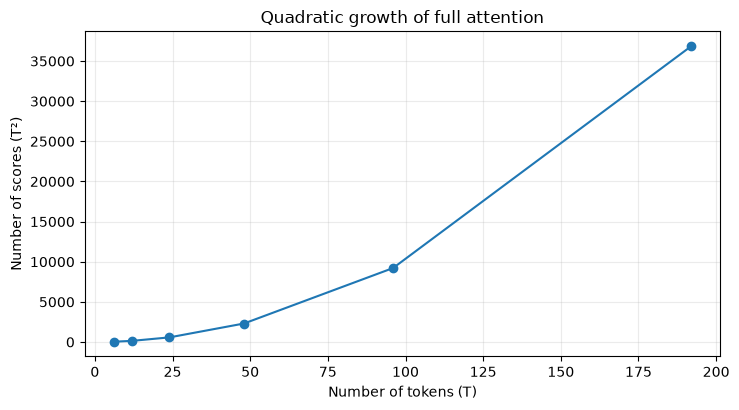

In [16]:
T_values = np.array([6, 12, 24, 48, 96, 192])
number_of_scores = T_values ** 2

for t, count in zip(T_values, number_of_scores):
    print(f"T={t:3d}  ->  scores={count:6d}")

# Illustrative memory estimate only: one dense T×T float32 score matrix.
for t in [1024, 2048]:
    mib = t*t*4 / (1024**2)
    print(f"T={t}: one float32 attention matrix ≈ {mib:.1f} MiB")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(T_values, number_of_scores, "o-")
ax.set_xlabel("Number of tokens (T)")
ax.set_ylabel("Number of scores (T²)")
ax.set_title("Quadratic growth of full attention")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_complexity.png", dpi=300)
plt.show()

## 14 · Otomatik kontroller

Boyutlar, satır toplamları, elle hesaplanan değerler, Jacobian ve çok başlı dikkat doğrulanır. Kod değişirse *Run All* ile yeniden çalıştırın.

In [17]:
checks = {
    "Input shape": X.shape == (6,8),
    "Q shape": Q.shape == (6,4),
    "K shape": K.shape == (6,4),
    "V shape": V.shape == (6,4),
    "Scores shape": S_raw.shape == (6,6),
    "Manual dot product": np.isclose(S_raw[2,4], Q[2] @ K[4]),
    "Scaled score": np.allclose(Z, S_raw / np.sqrt(D_K)),
    "Softmax row sums": np.allclose(A.sum(axis=1), 1.0),
    "Softmax nonnegative": np.all(A >= 0),
    "Output shape": O.shape == (6,4),
    "Manual output": np.allclose(O[2], manual_third),
    "Jacobian formula": np.isclose(softmax_jacobian(softmax_rows([2.,1.,0.]))[0,0],
                                    softmax_rows([2.,1.,0.])[0]*(1-softmax_rows([2.,1.,0.])[0])),
    "MHA concat shape": concat.shape == (6,8),
    "MHA final shape": final_output.shape == (6,8),
    "Different head maps": not np.allclose(head_attentions[0], head_attentions[1]),
    "Quadratic pair counts": np.array_equal(number_of_scores, T_values**2),
    "Jacobian finite difference": jacobian_fd_error < 1e-8,
    "Wide-head score = sum of head scores": np.allclose(Q_wide @ K_wide.T, sum_of_head_scores),
    "Two heads != one wide head": not np.allclose(A_one_wide, A_mean_heads),
}
for label, ok in checks.items():
    print(("PASS" if ok else "FAIL"), "—", label)
assert all(checks.values()), "One or more project checks failed"
print(f"\nAll {len(checks)}/{len(checks)} checks passed.")

PASS — Input shape
PASS — Q shape
PASS — K shape
PASS — V shape
PASS — Scores shape
PASS — Manual dot product
PASS — Scaled score
PASS — Softmax row sums
PASS — Softmax nonnegative
PASS — Output shape
PASS — Manual output
PASS — Jacobian formula
PASS — MHA concat shape
PASS — MHA final shape
PASS — Different head maps
PASS — Quadratic pair counts
PASS — Jacobian finite difference
PASS — Wide-head score = sum of head scores
PASS — Two heads != one wide head

All 19/19 checks passed.


## 15 · Sınırlılıklar ve kaynaklar

- Sentetik girdiler ve eğitilmemiş ağırlıklar kullanıldı; dil anlayışı ölçülmedi.
- Jacobian izi softmax'ın yerel duyarlılığını ölçer; modelin toplam gradyanı değildir.
- Bellek hesabı klasik, açıkça saklanan `T×T` matris içindir.

**Kaynaklar**

1. Hochreiter & Schmidhuber (1997), *Long Short-Term Memory*, Neural Computation.
2. Bahdanau, Cho & Bengio (2015), *Neural Machine Translation by Jointly Learning to Align and Translate*, ICLR.
3. Vaswani et al. (2017), *Attention Is All You Need*, NeurIPS.
4. Dao et al. (2022), *FlashAttention*, NeurIPS.